<div style="
    background-color: #7BAFD4;
    border-radius: 18px;
    padding: 22px 26px;
    display: flex;
    align-items: center;
    gap: 24px;
    margin-bottom: 18px;
">
    <img src="592_avatar_lr.png" alt="GEOG 592"
        style="width:110px;height:110px;border-radius:22px;">
    <div>
        <div style="
            font-family: Impact, 'Arial Black', Arial, sans-serif;
            font-size: 42px;
            font-weight: 900;
            letter-spacing: 2px;
            line-height: 1;
            color: white;
        ">GEOG 592</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 22px;
            font-weight: 700;
            color: #13294B;
            margin-top: 8px;
        ">GIS Programming</div>
        <div style="
            font-family: Arial, Helvetica, sans-serif;
            font-size: 16px;
            color: #13294B;
            margin-top: 6px;
        ">Cartography examples using GBIF and census data</div>
    </div>
</div>

## Charlotte Strom
## 10/21/26

# Research Question:

Both the Venus flytrap (Dionaea muscipula) and the Hooded pitcherplant (Sarracenia minor) are native carnivorous plants to North Carolina. The habitats which these plants thrive in is broadly considered wetlands, where there is wet, nutrient-poor soil, primarily in the coastal plain of North Carolina. Due to habitat destruction, attributed to the filling of wetlands for development, and the illegal poaching of the plants, the Venus flytrap and the Hooded pitcherplant are considered endangered. 

I want to explore how endangered carnivorous plants are affected by development and wetland loss in North Carolina through GBIF and species distribution data by creating four maps:

1. Distribution- Where is each species currently documented?

2. Overlap- Which counties have records of both species?

3. Historical records- Where are historical records documented?

4. Ecological- Do counties with documented occurrences of these two species also contain substantial wetland habitat?

# 1. Import Data 

In [22]:
# Loading Libraries
import time
import requests
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

In [23]:
### GBIF species occurrence data

species = ["Dionaea muscipula", "Sarracenia flava"]

api = "https://api.gbif.org/v1"
records = []

for name in species:

    # Find the GBIF taxon identifier
    response = requests.get(
        f"{api}/species/match",
        params={"name": name, "strict": "true"},
        timeout=60
    )
    response.raise_for_status()
    match = response.json()

    if match.get("rank") != "SPECIES":
        raise ValueError(f"Check the species name: {name}")

    taxon_key = match.get("acceptedUsageKey", match["usageKey"])

    # Define the occurrence search
    parameters = {
        "taxonKey": taxon_key,
        "country": "US",
        "stateProvince": "North Carolina",
        "occurrenceStatus": "PRESENT",
        "hasCoordinate": "true",
        "hasGeospatialIssue": "false",
        "limit": 300,
        "offset": 0
    }

    species_records = []

    while True:
        response = requests.get(
            f"{api}/occurrence/search",
            params=parameters,
            timeout=60
        )
        response.raise_for_status()
        page = response.json()

        if page["count"] > 9000:
            raise ValueError(
                f"{name} has too many records. "
                "Use a GBIF bulk download or narrow the search."
            )

        for record in page["results"]:
            record["queried_species"] = name

        species_records.extend(page["results"])

        if page.get("endOfRecords") or not page["results"]:
            break

        parameters["offset"] += len(page["results"])
        time.sleep(0.2)

    records.extend(species_records)

    print(f"{name}: {len(species_records):,} records")

Dionaea muscipula: 1,987 records
Sarracenia flava: 2,283 records


# 2. Select Important Columns

In [24]:
plants = pd.DataFrame(records)

plants = plants[
    [
        "queried_species",
        "decimalLongitude",
        "decimalLatitude",
        "year",
        "county",
        "basisOfRecord"
    ]
].copy()

plants.head()

,queried_species,decimalLongitude,decimalLatitude,year,county,basisOfRecord
0,Dionaea muscipula,-78.289579,34.135403,2026.0,NaN,HUMAN_OBSERVATION
1,Dionaea muscipula,-78.242698,34.013463,2026.0,NaN,HUMAN_OBSERVATION
2,Dionaea muscipula,-77.829090,34.072463,2026.0,NaN,HUMAN_OBSERVATION
3,Dionaea muscipula,-76.903033,34.760041,2026.0,NaN,HUMAN_OBSERVATION
4,Dionaea muscipula,-78.391138,34.157217,2026.0,NaN,HUMAN_OBSERVATION


# 3. Create GeoDataFrame

In [32]:
plant_points = gpd.GeoDataFrame(
    plants.copy(),
    geometry=gpd.points_from_xy(
        plants["decimalLongitude"],
        plants["decimalLatitude"]
    ),
    crs="EPSG:4326"
)

# Project to a coordinate system suitable for North Carolina
plant_points = plant_points.to_crs(epsg=6543)

# Remove records outside North Carolina's state boundary
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/"
url_state = "cb_2024_us_state_500k.zip"

states = gpd.read_file(url_0 + url_state)
nc_state = states.loc[states["STUSPS"] == "NC"].to_crs(epsg=6543)

plant_points = gpd.sjoin(
    plant_points,
    nc_state[["geometry"]],
    how="inner",
    predicate="within"
).drop(columns=["index_right"])

plant_points.head()

,queried_species,decimalLongitude,decimalLatitude,year,county,basisOfRecord,geometry
0,Dionaea muscipula,-78.289579,34.135403,2026.0,NaN,HUMAN_OBSERVATION,POINT (2214996.912 141041.677)
1,Dionaea muscipula,-78.242698,34.013463,2026.0,NaN,HUMAN_OBSERVATION,POINT (2229522.948 96767.534)
3,Dionaea muscipula,-76.903033,34.760041,2026.0,NaN,HUMAN_OBSERVATION,POINT (2629768.17 374252.09)
4,Dionaea muscipula,-78.391138,34.157217,2026.0,NaN,HUMAN_OBSERVATION,POINT (2184213.52 148776.442)
5,Dionaea muscipula,-78.380658,34.182564,2026.0,NaN,HUMAN_OBSERVATION,POINT (2187326.69 158020.813)


# 4. Load County Boundaries

In [36]:
# Load North Carolina county shapefile
nc_counties = gpd.read_file("/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/homework/Week09/NC_State_County_Boundary_NAD832011/NC_State_County_Boundary_NAD832011.shp")

# Check the columns and coordinate system
print(nc_counties.columns.tolist())
print(nc_counties.crs)

# Reproject to match the species points
nc_counties = nc_counties.to_crs(epsg=6543)

# Check the county names
nc_counties.head()

['OBJECTID', 'County', 'FIPS', 'Rec_Survey', 'NCGS_url', 'ck_date', 'Shape__Are', 'Shape__Len', 'GlobalID', 'geometry']
EPSG:6543


,OBJECTID,County,FIPS,Rec_Survey,NCGS_url,ck_date,Shape__Are,Shape__Len,GlobalID,geometry
0,1,Alamance,001,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13,1.210717e+10,476733.362073,acd66e2b-e702-4b3a-82c1-eb86e12d3804,"POLYGON ((1923605.17 881799.49, 1923342.02 867..."
1,2,Alexander,003,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13,7.343450e+09,387342.137292,6a1dac25-2574-4182-b77b-0074a5482dac,"POLYGON ((1374327.802 744224.777, 1374263.706 ..."
2,3,Alleghany,005,No recent survey data available,NaN,2011-11-29,6.576362e+09,439166.717185,d8e726fa-ac7d-4212-a981-6ea0b111cee0,"POLYGON ((1336458.502 959890.121, 1336579.893 ..."
3,4,Anson,007,No recent survey data available,NaN,2011-11-29,1.497020e+10,575503.754866,e4518706-732a-4abe-9079-9de6523b4747,"POLYGON ((1618559.88 528612.765, 1618623.885 5..."
4,5,Ashe,009,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,2025-01-13,1.193926e+10,520084.244333,6d39c7ea-b7f4-4ac8-be47-65dfe4a46074,"POLYGON ((1269471.85 915476.31, 1266825.82 915..."


# 5. Map 1: Distribution of Both Species

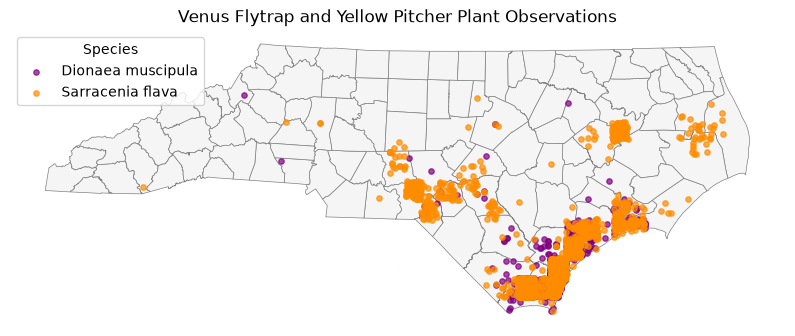

In [34]:
def pointMap(ax):

    nc_counties.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    colors = {
        "Dionaea muscipula": "purple",
        "Sarracenia flava": "darkorange"
    }

    for name, color in colors.items():
        plant_points.loc[
            plant_points["queried_species"] == name
        ].plot(
            ax=ax,
            color=color,
            markersize=15,
            alpha=0.7,
            label=name
        )

    ax.set_title("Venus Flytrap and Yellow Pitcher Plant Observations")
    ax.legend(title="Species")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
pointMap(ax)
plt.show()

# 6. Prepare County-Level Observation Counts

    County-level observation counts is needed for the next three maps.

In [39]:
points_by_county = gpd.sjoin(
    plant_points,
    nc_counties[["County", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns=["index_right"])

counts = (
    points_by_county
    .groupby(["County", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Dionaea muscipula", "Sarracenia flava"],
        fill_value=0
    )
)

counts.head()

queried_species,Dionaea muscipula,Sarracenia flava
County,,
Anson,0,1
Avery,1,0
Beaufort,0,35
Bladen,5,7
Brunswick,1002,976


# 7. Map 2: County-level Observations

    Note that the GBIF dataset contains only recorded observations. It does not represent actual plant population density.

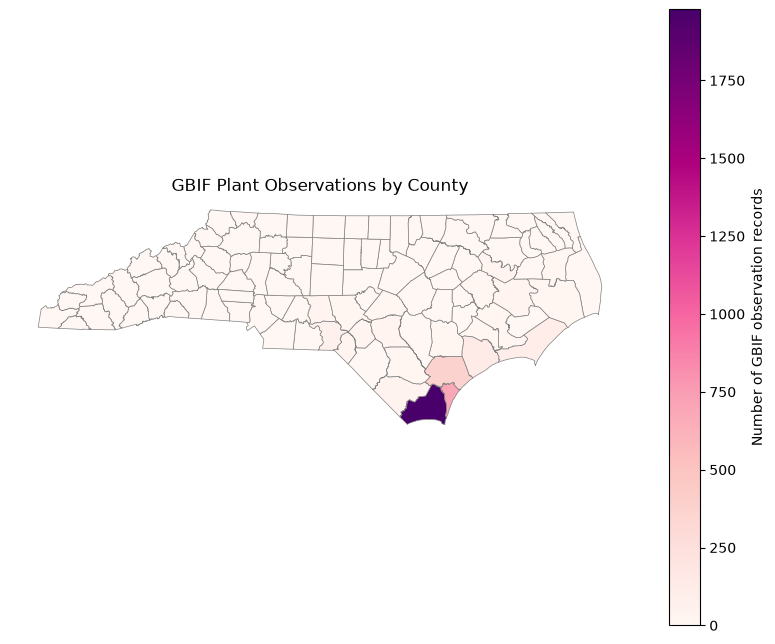

In [41]:
def countyCountMap(ax, nc_counties, counts):

    county_map = nc_counties.merge(
        counts,
        left_on="County",
        right_index=True,
        how="left"
    )

    species_columns = [
        "Dionaea muscipula",
        "Sarracenia flava"
    ]

    county_map[species_columns] = (
        county_map[species_columns].fillna(0)
    )

    county_map["total"] = county_map[species_columns].sum(axis=1)

    county_map.plot(
        column="total",
        cmap="RdPu",
        edgecolor="gray",
        linewidth=0.5,
        legend=True,
        legend_kwds={
            "label": "Number of GBIF observation records"
        },
        ax=ax
    )

    ax.set_title("GBIF Plant Observations by County")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
countyCountMap(ax, nc_counties, counts)
plt.show()

# 8. Map 3: Where do the two species overlap

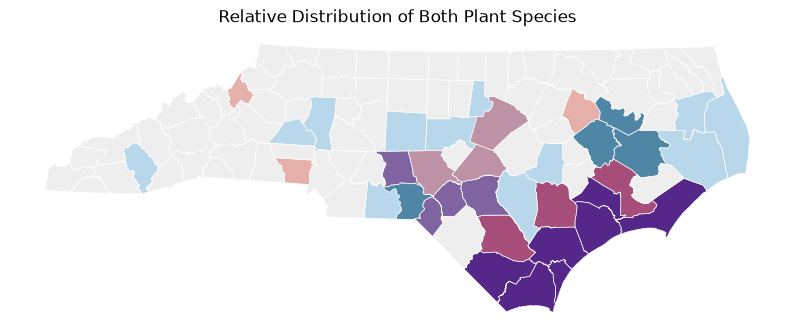

In [43]:
def overlapMap(ax, nc_counties, counts):

    bivariate = nc_counties.merge(
        counts,
        left_on="County",
        right_index=True,
        how="left"
    )

    species_columns = [
        "Dionaea muscipula",
        "Sarracenia flava"
    ]

    bivariate[species_columns] = (
        bivariate[species_columns].fillna(0)
    )

    for name in species_columns:
        values = bivariate[name]
        positive = values[values > 0]

        median = positive.median() if len(positive) else 0

        bivariate[name + "_class"] = np.select(
            [
                values == 0,
                (values > 0) & (values <= median)
            ],
            [0, 1],
            default=2
        )

    # Rows = Venus flytrap; columns = yellow pitcher plant
    palette = np.array([
        ["#eeeeee", "#b9d7ea", "#4f86a6"],
        ["#e6b0aa", "#bd91a6", "#8064a2"],
        ["#c0392b", "#a64d79", "#542788"]
    ])

    bivariate["color"] = [
        palette[venus, pitcher]
        for venus, pitcher in zip(
            bivariate["Dionaea muscipula_class"],
            bivariate["Sarracenia flava_class"]
        )
    ]

    bivariate.plot(
        color=bivariate["color"],
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )

    ax.set_title("Relative Distribution of Both Plant Species")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
overlapMap(ax, nc_counties, counts)
plt.show()

# 9. Map 4: Species Observations and Wetlands

/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/.venv/lib/python3.14/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'NC_geopackage_wetlands.gpkg': 'NC_Wetlands_Historic_Map_Info' (default), 'North_Carolina', 'NC_Wetlands', 'NC_Wetlands_Project_Metadata'. Specify layer parameter to avoid this warning.
  result = read_func(


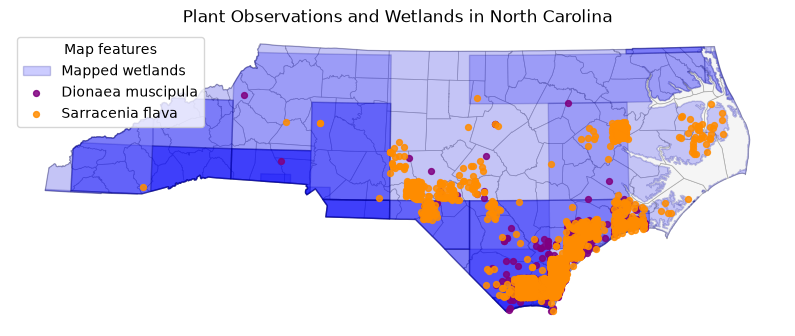

In [69]:
wetlands = gpd.read_file("/Users/Charlotte/Desktop/SeniorYear/GEOG_592/geog592-stromc/geog592-stromc/homework/Week09/NC_geopackage_wetlands.gpkg")

# Match the coordinate system of the county and point layers
wetlands = wetlands.to_crs(nc_counties.crs)

# Keep wetlands within North Carolina
wetlands = gpd.clip(wetlands, nc_state)


def wetlandMap(ax):

    nc_counties.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="darkgray",
        linewidth=0.5
    )

    wetlands.plot(
        ax=ax,
        color="blue",
        edgecolor="navy",
        alpha=0.2,
        label="Mapped wetlands"
    )

    colors = {
        "Dionaea muscipula": "purple",
        "Sarracenia flava": "darkorange"
    }

    for name, color in colors.items():
        plant_points.loc[
            plant_points["queried_species"] == name
        ].plot(
            ax=ax,
            color=color,
            markersize=18,
            alpha=0.85,
            label=name
        )

    ax.set_title("Plant Observations and Wetlands in North Carolina")
    ax.legend(title="Map features")
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(10, 8))
wetlandMap(ax)
plt.show()